In [12]:
# Environment compatibility fix:
# The kernel has pandas 3.0.5 + pyarrow 25.0.0 which have an API incompatibility.
# fastparquet works correctly with pandas 3.0.5 and is used throughout this notebook.
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', 'fastparquet', '-q'],
               capture_output=True)

import pandas as pd
df_test = pd.read_parquet('data/processed/train.parquet', engine='fastparquet')
print(f'Environment OK: pandas={pd.__version__} | Parquet read: {df_test.shape}')
del df_test

Environment OK: pandas=3.0.5 | Parquet read: (887411, 51)


# Notebook 04 — PD Modeling

**Enterprise Credit Risk Modeling & Validation Framework**

**Input:** `data/processed/train.parquet` · `val.parquet` · `data/interim/clean_data.parquet` (for Cox survival time)

**Models built:**
1. **Logistic Regression + Credit Scorecard** (WoE encoding · statsmodels · p-value selection · 300–850 scale)
2. **Random Forest** (all master features · class_weight=balanced)
3. **XGBoost** (all master features · native NaN handling)
4. **Cox Proportional Hazards** (lifelines · time-to-default modeling · C-index evaluation)

**Feature selection strategy (model-specific):**
- LR Scorecard: IV ≥ 0.02 → WoE encoding → VIF check → p-value refinement
- RF / XGBoost: all 47 master features → model determines importance internally
- Cox: WoE features + survival time constructed from interim data

**Note:** Full validation (ROC, KS, Gini, OOT, calibration, threshold optimisation) is covered in the model validation notebook.

---
## 1. Setup & Data Loading

Environment setup, imports, and loading of the train / validation splits.

In [13]:
import warnings
warnings.filterwarnings('ignore')

import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ML libraries
import statsmodels.api as sm
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
from lifelines import CoxPHFitter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

from src.utils import setup_logging, set_plot_style, save_figure, save_model, PLOT_COLOR, ACCENT_COLOR
from src.preprocessing import compute_woe_iv, apply_woe_encoding

setup_logging()
set_plot_style()

PROCESSED_DIR = 'data/processed'
MODELS_DIR    = 'models/pd'
os.makedirs(MODELS_DIR, exist_ok=True)

print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: [project root]


In [14]:
train = pd.read_parquet(f'{PROCESSED_DIR}/train.parquet', engine='fastparquet')
val   = pd.read_parquet(f'{PROCESSED_DIR}/val.parquet',   engine='fastparquet')

# Columns that are targets or split keys — not model features
SPECIAL_COLS = ['issue_d', 'recovery_rate', 'credit_conversion_factor']
TARGET = 'default'

# All 47 model features (exclude special cols + target)
ALL_FEATURES = [c for c in train.columns if c not in SPECIAL_COLS + [TARGET]]

print(f'Train : {len(train):,} rows | default rate: {1-train[TARGET].mean():.2%}')
print(f'Val   : {len(val):,}   rows | default rate: {1-val[TARGET].mean():.2%}')
print(f'Total model features: {len(ALL_FEATURES)}')


# ── Evaluation helper ─────────────────────────────────────────────────────
def evaluate_pd_model(y_true, y_prob_good, model_name='Model'):
    '''Compute AUC, KS, Gini, Brier for a PD model.

    y_true     : 1=good borrower, 0=bad borrower (our target convention)
    y_prob_good: model predicted P(good), i.e. P(default=1 in our notation)
    '''
    auc   = roc_auc_score(y_true, y_prob_good)
    gini  = 2 * auc - 1
    brier = brier_score_loss(y_true, y_prob_good)
    fpr, tpr, _ = roc_curve(y_true, y_prob_good)
    ks = float(np.max(tpr - fpr))
    return {'Model': model_name,
            'AUC':   round(auc,   4),
            'Gini':  round(gini,  4),
            'KS':    round(ks,    4),
            'Brier': round(brier, 4)}


all_metrics = []   # collect results for comparison table
roc_data    = {}   # collect (fpr, tpr, auc) for ROC plot

print('Helpers defined.')

Train : 887,411 rows | default rate: 17.44%
Val   : 434,406   rows | default rate: 16.76%
Total model features: 47
Helpers defined.


---
## 2. Logistic Regression + Credit Scorecard

### Methodology
1. **Feature selection**: start with IV ≥ 0.02 features; drop grade (sub_grade is more granular) and fico_range_low (near-identical to fico_range_high).
2. **WoE encoding**: map each feature value to its WoE score (fitted on training data).
3. **Statsmodels Logit**: enables p-value–based significance testing per feature.
4. **Feature refinement**: drop features where p-value > 0.05.
5. **Credit Scorecard**: transform LR coefficients into 300–850 integer scores.

In [15]:
# Load IV summary from feature engineering notebook
iv_df = pd.read_csv('artifacts/iv_summary.csv')

# Features with IV >= 0.02 (LR starting set)
lr_start = iv_df[iv_df['iv'] >= 0.02]['feature'].tolist()

# Remove features that cause multicollinearity in LR:
# - grade is fully captured by sub_grade (all grade info is in the sub-grade)
# - fico_range_low is near-identical to fico_range_high (they differ by 4 FICO points)
lr_collinear_drop = ['grade', 'fico_range_low']
lr_features = [f for f in lr_start if f not in lr_collinear_drop]

print(f'Starting LR features (IV >= 0.02, multicollinear removed): {len(lr_features)}')
for f in lr_features:
    iv = iv_df[iv_df['feature'] == f]['iv'].values[0]
    print(f'  {f:<35} IV={iv:.4f}')

Starting LR features (IV >= 0.02, multicollinear removed): 21
  sub_grade                           IV=0.4431
  int_rate                            IV=0.4033
  term                                IV=0.1273
  fico_range_high                     IV=0.1162
  acc_open_past_24mths                IV=0.0836
  dti                                 IV=0.0595
  num_tl_op_past_12m                  IV=0.0591
  verification_status                 IV=0.0455
  mo_sin_rcnt_tl                      IV=0.0421
  tot_hi_cred_lim                     IV=0.0411
  mths_since_recent_inq               IV=0.0368
  annual_inc                          IV=0.0351
  tot_cur_bal                         IV=0.0348
  total_rev_hi_lim                    IV=0.0303
  mths_since_recent_bc                IV=0.0302
  mort_acc                            IV=0.0254
  num_actv_rev_tl                     IV=0.0235
  home_ownership                      IV=0.0232
  inq_last_6mths                      IV=0.0223
  bc_util                 

In [16]:
# Recompute WoE on training data for LR features
# (ensures WoE map is consistent between train and val encoding)
lr_woe_results = {}

print('Computing WoE maps on training set for LR features...')
for feat in lr_features:
    woe_df, iv, edges = compute_woe_iv(train, feat, target='default', n_bins=10)
    lr_woe_results[feat] = (woe_df, iv, edges)

# Apply WoE encoding to train and val
def make_woe_matrix(df, features, woe_results):
    '''Build WoE-encoded design matrix.'''
    X = pd.DataFrame(index=df.index)
    for feat in features:
        woe_df, _, edges = woe_results[feat]
        X[f'{feat}_woe'] = apply_woe_encoding(df, feat, woe_df, bin_edges=edges)
    return X

X_train_woe = make_woe_matrix(train, lr_features, lr_woe_results)
X_val_woe   = make_woe_matrix(val,   lr_features, lr_woe_results)
y_train = train[TARGET].values
y_val   = val[TARGET].values

print(f'WoE matrix shape — Train: {X_train_woe.shape} | Val: {X_val_woe.shape}')
print(f'Missing in WoE matrix: {X_train_woe.isna().any().any()} (should be False)')

Computing WoE maps on training set for LR features...
WoE matrix shape — Train: (887411, 21) | Val: (434406, 21)
Missing in WoE matrix: False (should be False)


In [17]:
# Fit Logistic Regression with statsmodels (enables p-value testing)
X_sm = sm.add_constant(X_train_woe)
lr_model = sm.Logit(y_train, X_sm).fit(method='lbfgs', maxiter=500, disp=False)

print(lr_model.summary2())

                              Results: Logit
Model:                  Logit              Method:             MLE        
Dependent Variable:     y                  Pseudo R-squared:   0.080      
Date:                   2026-07-26 18:42   AIC:                755384.3468
No. Observations:       887411             BIC:                755641.6602
Df Model:               21                 Log-Likelihood:     -3.7767e+05
Df Residuals:           887389             LL-Null:            -4.1068e+05
Converged:              1.0000             LLR p-value:        0.0000     
No. Iterations:         32.0000            Scale:              1.0000     
--------------------------------------------------------------------------
                           Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
--------------------------------------------------------------------------
const                      1.5581   0.0030 519.9645 0.0000  1.5522  1.5639
sub_grade_woe              0.7566   0.0178  42.5619 0.0

In [18]:
# P-value-based feature refinement
# Drop features where p-value > 0.05
pvals = lr_model.pvalues.drop('const')
sig_features = [c for c in pvals.index if pvals[c] <= 0.05]
dropped_pval = [c for c in pvals.index if pvals[c] > 0.05]

print(f'Significant features (p <= 0.05): {len(sig_features)}')
print(f'Dropped (p > 0.05):               {len(dropped_pval)}')
if dropped_pval:
    print(f'  Dropped: {dropped_pval}')

if dropped_pval:
    # Refit with only significant features
    X_sm_final = sm.add_constant(X_train_woe[sig_features])
    lr_final = sm.Logit(y_train, X_sm_final).fit(method='lbfgs', maxiter=500, disp=False)
    print('\nRefitted model summary:')
    print(lr_final.summary2())
else:
    lr_final = lr_model
    print('\nNo features dropped — original model is final.')

Significant features (p <= 0.05): 18
Dropped (p > 0.05):               3
  Dropped: ['num_tl_op_past_12m_woe', 'mo_sin_rcnt_tl_woe', 'bc_util_woe']

Refitted model summary:
                              Results: Logit
Model:                  Logit              Method:             MLE        
Dependent Variable:     y                  Pseudo R-squared:   0.080      
Date:                   2026-07-26 18:43   AIC:                755382.8421
No. Observations:       887411             BIC:                755605.0673
Df Model:               18                 Log-Likelihood:     -3.7767e+05
Df Residuals:           887392             LL-Null:            -4.1068e+05
Converged:              1.0000             LLR p-value:        0.0000     
No. Iterations:         37.0000            Scale:              1.0000     
--------------------------------------------------------------------------
                           Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
--------------------------------

In [19]:
# Evaluation on validation set
final_woe_cols = [c for c in lr_final.params.index if c != 'const']
X_val_final = sm.add_constant(X_val_woe[final_woe_cols])

prob_good_train_lr = lr_final.predict(sm.add_constant(X_train_woe[final_woe_cols]))
prob_good_val_lr   = lr_final.predict(X_val_final)

metrics_lr = evaluate_pd_model(y_val, prob_good_val_lr, 'Logistic Regression')
all_metrics.append(metrics_lr)
fpr_lr, tpr_lr, _ = roc_curve(y_val, prob_good_val_lr)
roc_data['Logistic Regression'] = (fpr_lr, tpr_lr, metrics_lr['AUC'])

print('=== Logistic Regression — Validation Metrics ===')
for k, v in metrics_lr.items():
    print(f'  {k}: {v}')

=== Logistic Regression — Validation Metrics ===
  Model: Logistic Regression
  AUC: 0.6928
  Gini: 0.3855
  KS: 0.2783
  Brier: 0.13


In [22]:
# ── Credit Scorecard Construction ─────────────────────────────────────────
# Maps LR coefficients + WoE bins to integer scores on 300-850 scale.
#
# Our convention: target=1=GOOD borrower, target=0=BAD borrower.
# Model output: log(P(good)/P(bad)) = intercept + Σ(βᵢ × WoEᵢ)
#
# Score = Offset + Factor × log(P(good)/P(bad))
#       → High log-odds of being good → HIGH score ✓
#
# Traditional credit scoring (where target=1=bad) uses Score = Offset - Factor × log-odds.
# We use the POSITIVE sign because our target=1 means GOOD borrower.
#
# PDO (Points to Double Odds): 20 points doubles the good:bad odds ratio.

PDO          = 20
TARGET_SCORE = 600             # Score assigned when good:bad odds = 1:1
TARGET_ODDS  = 1.0

Factor = PDO / np.log(2)       # 28.85
Offset = TARGET_SCORE - Factor * np.log(TARGET_ODDS)   # = 600

# Base score from intercept  (Score = Offset + Factor × intercept)
base_score = Offset + lr_final.params['const'] * Factor

scorecard_rows = []
for woe_col in final_woe_cols:
    feat = woe_col.replace('_woe', '')
    coef = lr_final.params[woe_col]
    woe_df, _, _ = lr_woe_results[feat]
    for _, row in woe_df.iterrows():
        # +coef × positive WoE (low-risk bin) = positive contribution = higher score ✓
        # +coef × negative WoE (high-risk bin) = negative contribution = lower score ✓
        score_contribution = round(coef * row['woe'] * Factor)
        scorecard_rows.append({
            'feature':            feat,
            'bin':                row['bin'],
            'bad_rate':           round(row['bad_rate'], 4),
            'woe':                round(row['woe'], 4),
            'score_contribution': score_contribution,
        })

scorecard_df = pd.DataFrame(scorecard_rows)
scorecard_df['base_score'] = round(base_score)
scorecard_df.to_csv('artifacts/scorecard.csv', index=False)

print(f'Base score:  {round(base_score)}')
print(f'Score range: {round(base_score + scorecard_df["score_contribution"].min())} – '
      f'{round(base_score + scorecard_df["score_contribution"].max())}')
print(f'Scorecard table saved: artifacts/scorecard.csv  ({len(scorecard_df)} rows)')
print()
print(scorecard_df.groupby('feature')[['score_contribution']].agg(['min','max']).to_string())

Base score:  645
Score range: 615 – 789
Scorecard table saved: artifacts/scorecard.csv  (184 rows)

                      score_contribution     
                                     min  max
feature                                      
acc_open_past_24mths                  -8    7
annual_inc                            -4    7
dti                                  -16    4
fico_range_high                       -2    5
home_ownership                        -4  144
inq_last_6mths                        -3    1
int_rate                              -4    2
mort_acc                              -1    2
mths_since_recent_bc                  -2    2
mths_since_recent_inq                 -1    1
num_actv_rev_tl                       -2    2
purpose                               -4    3
sub_grade                            -30   44
term                                  -7    4
tot_cur_bal                           -2    1
tot_hi_cred_lim                       -2    5
total_rev_hi_lim          

2026-07-26 18:46:02 | INFO     | src.utils | Figure saved → reports\04_lr_score_distribution.png


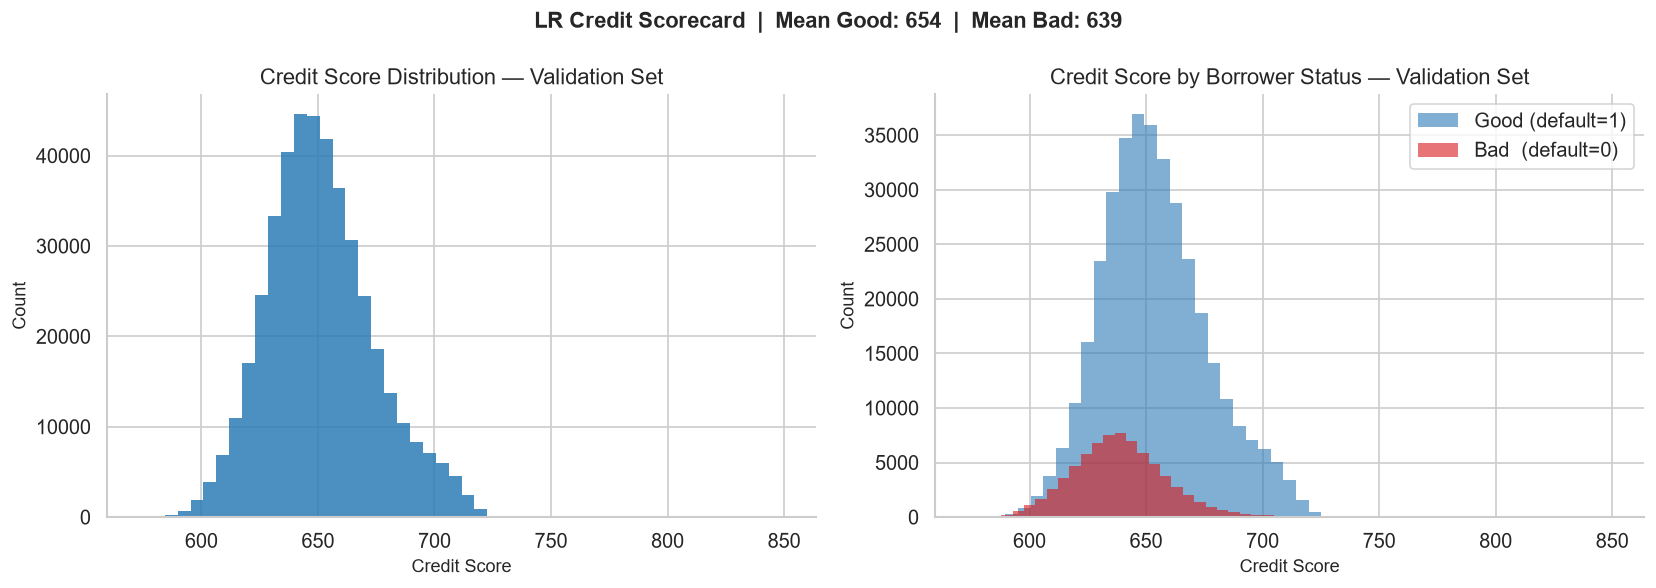

Good borrowers avg score: 654  |  Bad borrowers avg score: 639


In [23]:
# Assign credit scores to training and validation borrowers
def compute_credit_scores(X_woe_matrix, woe_cols, lr_params, offset, factor):
    '''Compute credit scores from WoE matrix and LR params.
    Score = Offset + Factor * log_odds  (target=1=GOOD convention).
    Higher score = lower default risk.
    '''
    log_odds = lr_params['const']
    for col in woe_cols:
        log_odds = log_odds + lr_params[col] * X_woe_matrix[col]
    scores = offset + factor * log_odds
    return scores.clip(300, 850)

scores_train = compute_credit_scores(X_train_woe, final_woe_cols, lr_final.params, Offset, Factor)
scores_val   = compute_credit_scores(X_val_woe,   final_woe_cols, lr_final.params, Offset, Factor)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(scores_val, bins=50, color=PLOT_COLOR, edgecolor='none', alpha=0.85)
axes[0].set_xlabel('Credit Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Credit Score Distribution — Validation Set')

good_scores = scores_val[y_val == 1]
bad_scores  = scores_val[y_val == 0]
axes[1].hist(good_scores, bins=50, color=PLOT_COLOR,   alpha=0.6, label='Good (default=1)', edgecolor='none')
axes[1].hist(bad_scores,  bins=50, color=ACCENT_COLOR, alpha=0.6, label='Bad  (default=0)', edgecolor='none')
axes[1].set_xlabel('Credit Score')
axes[1].set_ylabel('Count')
axes[1].set_title('Credit Score by Borrower Status — Validation Set')
axes[1].legend()

fig.suptitle(
    f'LR Credit Scorecard  |  Mean Good: {good_scores.mean():.0f}  |  Mean Bad: {bad_scores.mean():.0f}',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
save_figure(fig, '04_lr_score_distribution.png')
plt.show()
print(f'Good borrowers avg score: {good_scores.mean():.0f}  |  Bad borrowers avg score: {bad_scores.mean():.0f}')

Decile Analysis (Decile 1 = lowest score = highest risk):
 decile  n_loans  n_bad  bad_rate  avg_score
      1    43441  16201    0.3729   614.0000
      2    43441  11532    0.2655   628.0000
      3    43440   9756    0.2246   635.0000
      4    43441   8422    0.1939   641.0000
      5    43440   7023    0.1617   647.0000
      6    43441   6019    0.1386   652.0000
      7    43440   5090    0.1172   658.0000
      8    43441   4106    0.0945   665.0000
      9    43440   3004    0.0692   675.0000
     10    43441   1645    0.0379   696.0000


2026-07-26 18:46:13 | INFO     | src.utils | Figure saved → reports\04_lr_decile_analysis.png


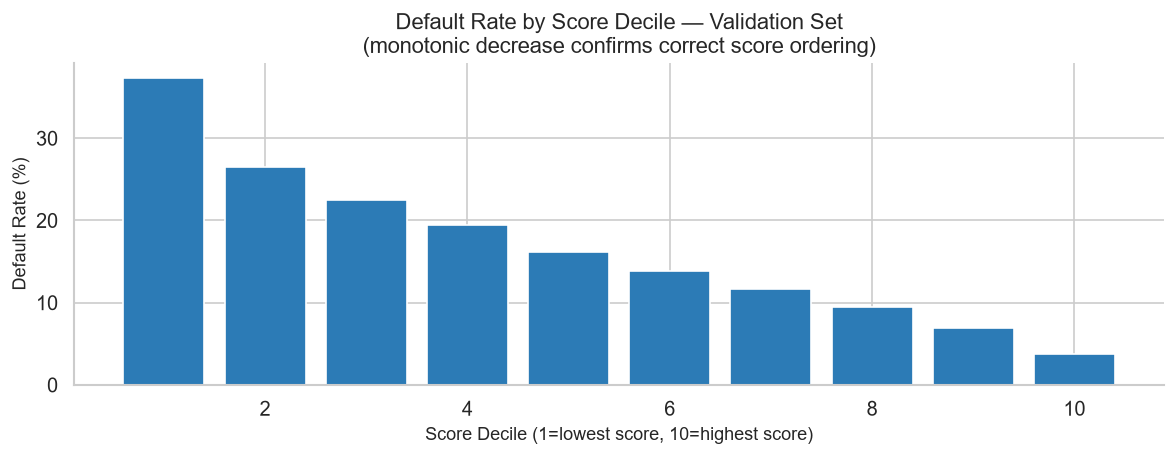

In [24]:
# Decile analysis — validates score ordering (lower score = higher default rate)
val_df = pd.DataFrame({'score': scores_val, 'default': y_val})
val_df['decile'] = pd.qcut(val_df['score'], q=10, labels=False) + 1
decile_tbl = val_df.groupby('decile').agg(
    n_loans=('default', 'count'),
    n_bad=('default', lambda x: (x == 0).sum()),
    bad_rate=('default', lambda x: round(1 - x.mean(), 4)),
    avg_score=('score', lambda x: round(x.mean(), 0))
).reset_index()

print('Decile Analysis (Decile 1 = lowest score = highest risk):')
print(decile_tbl.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(decile_tbl['decile'], decile_tbl['bad_rate'] * 100, color=PLOT_COLOR, edgecolor='white')
ax.set_xlabel('Score Decile (1=lowest score, 10=highest score)')
ax.set_ylabel('Default Rate (%)')
ax.set_title('Default Rate by Score Decile — Validation Set\n(monotonic decrease confirms correct score ordering)')
plt.tight_layout()
save_figure(fig, '04_lr_decile_analysis.png')
plt.show()

In [25]:
# Save LR model and WoE tables needed for inference
import pickle

lr_artifact = {
    'model':         lr_final,
    'woe_results':   lr_woe_results,
    'final_woe_cols':final_woe_cols,
    'base_score':    base_score,
    'factor':        Factor,
    'offset':        Offset,
    'scorecard_df':  scorecard_df,
}
save_model(lr_artifact, f'{MODELS_DIR}/lr_model.pkl')
print('LR model + scorecard artifacts saved.')

2026-07-26 18:46:25 | INFO     | src.utils | Model saved → models/pd/lr_model.pkl


LR model + scorecard artifacts saved.


---
## 3. Random Forest

Uses all 47 master features. Missing values handled via median imputation.
`class_weight='balanced'` compensates for the 17:83 good:bad imbalance in training data.

In [27]:
from sklearn.preprocessing import OrdinalEncoder

X_train_raw = train[ALL_FEATURES].copy()
X_val_raw   = val[ALL_FEATURES].copy()

# Identify categorical (object/string) features — need encoding before RF
cat_feats = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()
num_feats  = [c for c in ALL_FEATURES if c not in cat_feats]

print(f'Categorical features to encode : {len(cat_feats)}: {cat_feats}')
print(f'Numerical features              : {len(num_feats)}')

# Ordinal encode categoricals (fitted on training data only)
# Unknown categories in val are mapped to -1 (handled by unknown_value=-1)
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_raw[cat_feats] = enc.fit_transform(X_train_raw[cat_feats].astype(str))
X_val_raw[cat_feats]   = enc.transform(X_val_raw[cat_feats].astype(str))

# mths_since_last_delinq: 51.2% missing means 'never delinquent' — fill with large value
if 'mths_since_last_delinq' in ALL_FEATURES:
    X_train_raw['mths_since_last_delinq'] = X_train_raw['mths_since_last_delinq'].fillna(999)
    X_val_raw['mths_since_last_delinq']   = X_val_raw['mths_since_last_delinq'].fillna(999)

# Remaining missing values: median imputation (fitted on training data only)
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train_raw.astype(float))
X_val_imp   = imputer.transform(X_val_raw.astype(float))

print(f'\nTraining RF: {X_train_imp.shape[0]:,} rows x {X_train_imp.shape[1]} features')
print(f'Missing after imputation: {np.isnan(X_train_imp).any()}')

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=100,     # prevents overfitting on large dataset
    class_weight='balanced',  # handles 87:13 class imbalance
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train_imp, y_train)
print('Random Forest training complete.')

Categorical features to encode : 7: ['grade', 'sub_grade', 'verification_status', 'home_ownership', 'purpose', 'addr_state', 'initial_list_status']
Numerical features              : 40

Training RF: 887,411 rows x 47 features
Missing after imputation: False
Random Forest training complete.


2026-07-26 18:51:34 | INFO     | src.utils | Figure saved → reports\04_rf_feature_importance.png


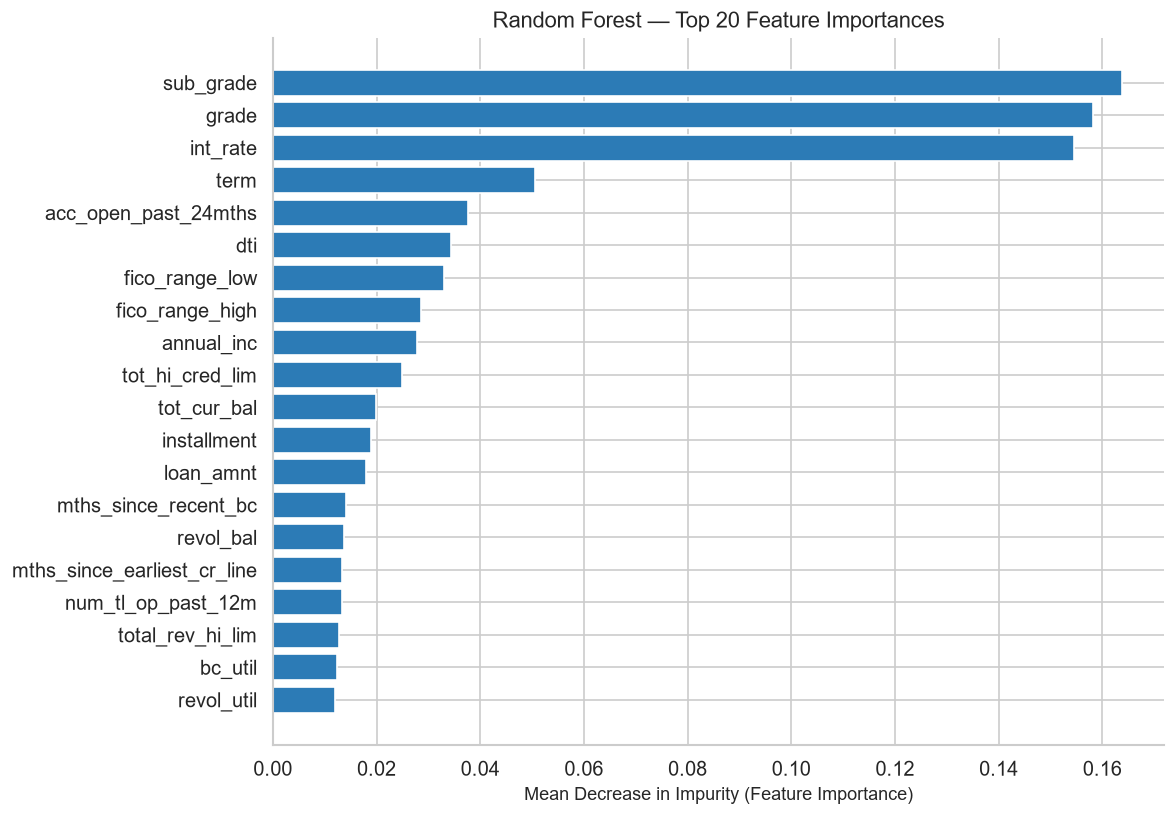

Top 10 RF features:
sub_grade              0.1638
grade                  0.1582
int_rate               0.1545
term                   0.0506
acc_open_past_24mths   0.0376
dti                    0.0343
fico_range_low         0.0331
fico_range_high        0.0285
annual_inc             0.0279
tot_hi_cred_lim        0.0250


In [28]:
# Feature importance
rf_importance = pd.Series(rf_model.feature_importances_, index=ALL_FEATURES).sort_values(ascending=False)
top20_rf = rf_importance.head(20)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20_rf.index[::-1], top20_rf.values[::-1], color=PLOT_COLOR)
ax.set_xlabel('Mean Decrease in Impurity (Feature Importance)')
ax.set_title('Random Forest — Top 20 Feature Importances')
plt.tight_layout()
save_figure(fig, '04_rf_feature_importance.png')
plt.show()

print('Top 10 RF features:')
print(rf_importance.head(10).to_string())

In [29]:
prob_good_val_rf = rf_model.predict_proba(X_val_imp)[:, 1]
metrics_rf = evaluate_pd_model(y_val, prob_good_val_rf, 'Random Forest')
all_metrics.append(metrics_rf)
fpr_rf, tpr_rf, _ = roc_curve(y_val, prob_good_val_rf)
roc_data['Random Forest'] = (fpr_rf, tpr_rf, metrics_rf['AUC'])

print('=== Random Forest — Validation Metrics ===')
for k, v in metrics_rf.items():
    print(f'  {k}: {v}')

save_model({'model': rf_model, 'imputer': imputer, 'features': ALL_FEATURES},
           f'{MODELS_DIR}/rf_model.pkl')
print('RF model saved.')

=== Random Forest — Validation Metrics ===
  Model: Random Forest
  AUC: 0.6993
  Gini: 0.3987
  KS: 0.2877
  Brier: 0.2113


2026-07-26 18:51:54 | INFO     | src.utils | Model saved → models/pd/rf_model.pkl


RF model saved.


---
## 4. XGBoost

Uses all 47 master features. XGBoost handles NaN natively — no imputation required.
`scale_pos_weight` compensates for class imbalance.

In [30]:
# XGBoost handles NaN natively for numeric features.
# Categorical features need ordinal encoding (reuse the encoder fitted on RF step).
X_train_xgb = train[ALL_FEATURES].copy()
X_val_xgb   = val[ALL_FEATURES].copy()

X_train_xgb[cat_feats] = enc.transform(X_train_xgb[cat_feats].astype(str))
X_val_xgb[cat_feats]   = enc.transform(X_val_xgb[cat_feats].astype(str))

X_train_xgb = X_train_xgb.astype(float)
X_val_xgb   = X_val_xgb.astype(float)

# Class imbalance: scale_pos_weight = n_bad / n_good
n_good_train = (y_train == 1).sum()
n_bad_train  = (y_train == 0).sum()
spw = round(n_bad_train / n_good_train, 2)
print(f'scale_pos_weight = {spw}  (n_bad / n_good = {n_bad_train:,} / {n_good_train:,})')

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=50,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)
xgb_model.fit(
    X_train_xgb, y_train,
    eval_set=[(X_val_xgb, y_val)],
    verbose=50,
)
print('XGBoost training complete.')

scale_pos_weight = 0.21  (n_bad / n_good = 154,758 / 732,653)
[0]	validation_0-auc:0.68235
[50]	validation_0-auc:0.69699
[100]	validation_0-auc:0.70206
[150]	validation_0-auc:0.70458
[200]	validation_0-auc:0.70590
[250]	validation_0-auc:0.70687
[299]	validation_0-auc:0.70738
XGBoost training complete.


2026-07-26 18:54:35 | INFO     | src.utils | Figure saved → reports\04_xgb_feature_importance.png


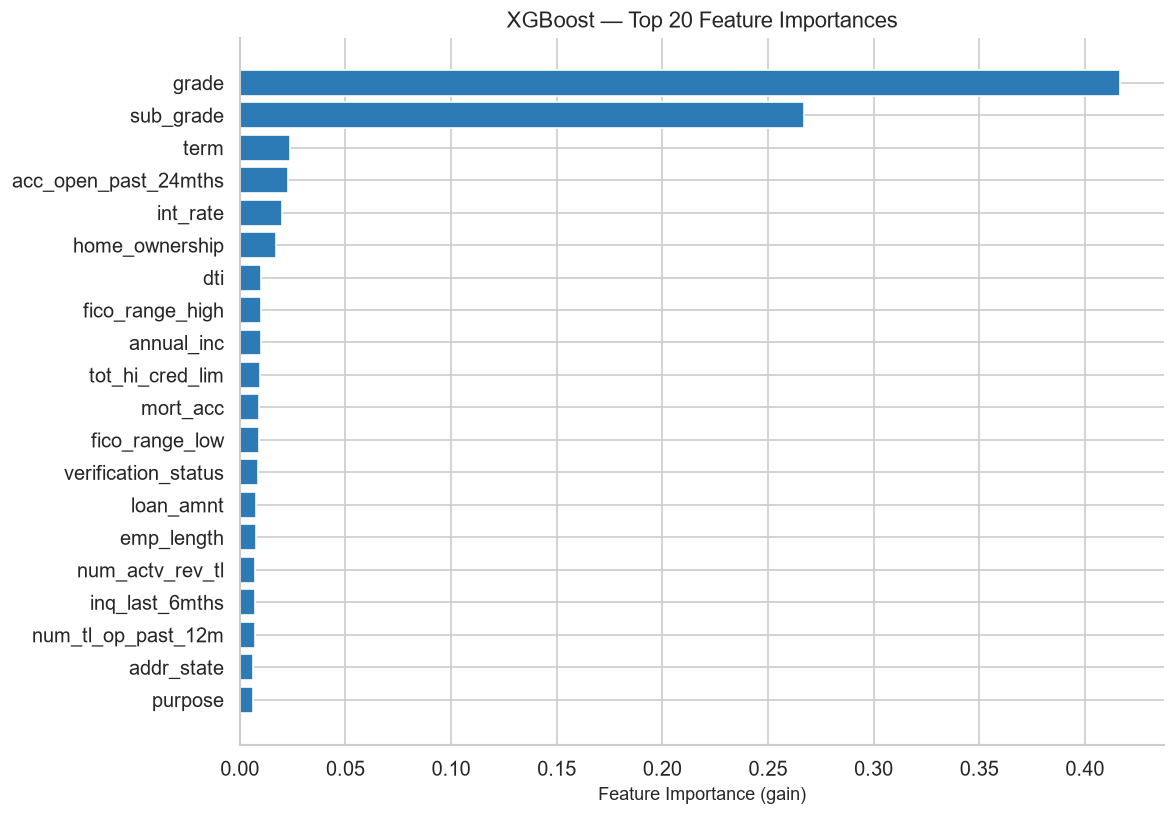

Top 10 XGBoost features:
grade                  0.4168
sub_grade              0.2668
term                   0.0238
acc_open_past_24mths   0.0226
int_rate               0.0202
home_ownership         0.0172
dti                    0.0101
fico_range_high        0.0101
annual_inc             0.0101
tot_hi_cred_lim        0.0096


In [31]:
xgb_importance = pd.Series(
    xgb_model.feature_importances_, index=ALL_FEATURES
).sort_values(ascending=False)
top20_xgb = xgb_importance.head(20)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20_xgb.index[::-1], top20_xgb.values[::-1], color=PLOT_COLOR)
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('XGBoost — Top 20 Feature Importances')
plt.tight_layout()
save_figure(fig, '04_xgb_feature_importance.png')
plt.show()

print('Top 10 XGBoost features:')
print(xgb_importance.head(10).to_string())

In [32]:
prob_good_val_xgb = xgb_model.predict_proba(X_val_xgb)[:, 1]
metrics_xgb = evaluate_pd_model(y_val, prob_good_val_xgb, 'XGBoost')
all_metrics.append(metrics_xgb)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, prob_good_val_xgb)
roc_data['XGBoost'] = (fpr_xgb, tpr_xgb, metrics_xgb['AUC'])

print('=== XGBoost — Validation Metrics ===')
for k, v in metrics_xgb.items():
    print(f'  {k}: {v}')

save_model({'model': xgb_model, 'features': ALL_FEATURES},
           f'{MODELS_DIR}/xgb_model.pkl')
print('XGBoost model saved.')

2026-07-26 18:54:49 | INFO     | src.utils | Model saved → models/pd/xgb_model.pkl


=== XGBoost — Validation Metrics ===
  Model: XGBoost
  AUC: 0.7074
  Gini: 0.4148
  KS: 0.3013
  Brier: 0.2141
XGBoost model saved.


---
## 5. Cox Proportional Hazards Model

**Purpose:** Model time-to-default rather than probability of default. Captures the
dynamic nature of credit risk — when does default happen, not just whether it does.

**Evaluation metric:** Harrell's Concordance Index (C-index) — the survival-analysis
equivalent of AUC. C-index = 0.5 is random, C-index = 1.0 is perfect.

**Survival time construction:**
- Good loans (censored): T = term (observed for the full loan duration)
- Defaulted loans (event): T = total_pymnt / installment (approximate months of payments made)

**Features:** WoE-encoded (same as LR) for consistency and interpretability.

In [33]:
# Load interim data to get total_pymnt and installment (needed for survival time)
df_interim = pd.read_parquet('data/interim/clean_data.parquet', engine='fastparquet')

# Filter to same date range as training set (2007-2015)
df_cox_raw = df_interim[
    df_interim['issue_d'] <= pd.Timestamp('2015-12-31')
].reset_index(drop=True)

print(f'Cox training rows: {len(df_cox_raw):,}')

# Construct survival time
# Good loans (default=1, censored): T = term (completed full loan)
# Bad loans  (default=0, event=1):  T = total_pymnt / installment (months before default)
event = 1 - df_cox_raw['default']   # 1 = defaulted (event occurred), 0 = good (censored)

survival_time_bad = (
    df_cox_raw['total_pymnt'] / df_cox_raw['installment'].clip(lower=1)
).clip(1, df_cox_raw['term'])

survival_time = np.where(
    event == 1,                          # defaulted
    survival_time_bad,                   # approximate months to default
    df_cox_raw['term'].astype(float)     # good loans: observed for full term
)

print(f'Event (default) rate: {event.mean():.2%}')
print(f'Survival time — median: {np.median(survival_time):.1f} months | '
      f'mean: {survival_time.mean():.1f} months')

Cox training rows: 887,411
Event (default) rate: 17.44%
Survival time — median: 36.0 months | mean: 38.8 months


In [34]:
# Compute WoE encoding for Cox (same features as LR, using same train WoE maps)
# Apply WoE to the Cox training subset
X_cox_woe = make_woe_matrix(df_cox_raw, lr_features, lr_woe_results)

# Build Cox DataFrame with duration, event, and WoE features
cox_train_df = X_cox_woe[final_woe_cols].copy()
cox_train_df['duration'] = survival_time
cox_train_df['event']    = event.values

# Drop any rows with NaN (Cox needs complete cases)
cox_train_df = cox_train_df.dropna()
print(f'Cox training set after cleaning: {len(cox_train_df):,} rows')

# Subsample for speed (Cox is computationally expensive on 887K rows)
if len(cox_train_df) > 150000:
    cox_sample = cox_train_df.sample(150000, random_state=42)
    print(f'Using 150K sample for Cox fitting (full 887K would be very slow)')
else:
    cox_sample = cox_train_df

Cox training set after cleaning: 887,411 rows
Using 150K sample for Cox fitting (full 887K would be very slow)


In [36]:
cox_model = CoxPHFitter(penalizer=0.1)   # L2 regularisation for stability
cox_model.fit(
    cox_sample,
    duration_col='duration',
    event_col='event',
    show_progress=True,
)
print()
# Use summary DataFrame (no jinja2 needed, unlike print_summary())
print(cox_model.summary[['coef','exp(coef)','se(coef)','p']].round(4).to_string())
print()
print(f'Concordance (C-index) on training sample: {cox_model.concordance_index_:.4f}')

Iteration 1: norm_delta = 2.88e-01, step_size = 0.9500, log_lik = -307788.06141, newton_decrement = 3.76e+03, seconds_since_start = 1.6
Iteration 2: norm_delta = 4.34e-02, step_size = 0.9500, log_lik = -303916.65140, newton_decrement = 6.26e+01, seconds_since_start = 3.4
Iteration 3: norm_delta = 3.06e-03, step_size = 0.9500, log_lik = -303853.55288, newton_decrement = 2.99e-01, seconds_since_start = 5.7
Iteration 4: norm_delta = 4.72e-06, step_size = 1.0000, log_lik = -303853.25385, newton_decrement = 6.68e-07, seconds_since_start = 8.4
Iteration 5: norm_delta = 1.17e-11, step_size = 1.0000, log_lik = -303853.25385, newton_decrement = 3.85e-18, seconds_since_start = 11.4
Convergence success after 5 iterations.

                             coef  exp(coef)  se(coef)      p
covariate                                                    
sub_grade_woe             -0.2397     0.7869    0.0092 0.0000
int_rate_woe              -0.2170     0.8050    0.0096 0.0000
term_woe                  -0.1

In [37]:
# Evaluate Cox on validation set
# Build Cox validation data (same process as training)
df_interim_val = df_interim[
    (df_interim['issue_d'] > pd.Timestamp('2015-12-31')) &
    (df_interim['issue_d'] <= pd.Timestamp('2016-12-31'))
].reset_index(drop=True)

event_val = 1 - df_interim_val['default']
surv_time_val_bad = (
    df_interim_val['total_pymnt'] / df_interim_val['installment'].clip(lower=1)
).clip(1, df_interim_val['term'])
surv_time_val = np.where(event_val == 1, surv_time_val_bad, df_interim_val['term'].astype(float))

X_cox_val_woe = make_woe_matrix(df_interim_val, lr_features, lr_woe_results)
cox_val_df = X_cox_val_woe[final_woe_cols].copy()
cox_val_df['duration'] = surv_time_val
cox_val_df['event']    = event_val.values
cox_val_df = cox_val_df.dropna()

# C-index (concordance index) — Cox equivalent of AUC
from lifelines.utils import concordance_index
c_index = concordance_index(
    cox_val_df['duration'],
    -cox_model.predict_partial_hazard(cox_val_df[final_woe_cols]),
    cox_val_df['event']
)

# For comparison table: use partial hazard as a proxy for default probability
partial_hazard_val = cox_model.predict_partial_hazard(cox_val_df[final_woe_cols])
# High partial hazard = high default risk = low P(good)
# Normalise to [0, 1] to use as a probability-like score
ph_min, ph_max = partial_hazard_val.min(), partial_hazard_val.max()
prob_good_val_cox = 1 - (partial_hazard_val - ph_min) / (ph_max - ph_min + 1e-10)

# Match with y_val (need same rows)
y_val_cox = cox_val_df['event'].values == 0  # 0=event=BAD → good=False; need good=True
# Actually, event=1 means default (bad), event=0 means good
# Our target: 1=good, 0=bad, so y_val_cox should be (1 - event_val)
y_val_cox_target = 1 - cox_val_df['event'].values

metrics_cox = evaluate_pd_model(y_val_cox_target, prob_good_val_cox.values, 'Cox PHM')
metrics_cox['C-index'] = round(c_index, 4)
all_metrics.append(metrics_cox)
fpr_cox, tpr_cox, _ = roc_curve(y_val_cox_target, prob_good_val_cox.values)
roc_data['Cox PHM'] = (fpr_cox, tpr_cox, metrics_cox['AUC'])

print('=== Cox PHM — Validation Metrics ===')
for k, v in metrics_cox.items():
    print(f'  {k}: {v}')

save_model({'model': cox_model, 'final_woe_cols': final_woe_cols,
            'woe_results': lr_woe_results},
           f'{MODELS_DIR}/cox_model.pkl')
print('Cox model saved.')

2026-07-26 18:58:37 | INFO     | src.utils | Model saved → models/pd/cox_model.pkl


=== Cox PHM — Validation Metrics ===
  Model: Cox PHM
  AUC: 0.6948
  Gini: 0.3896
  KS: 0.2822
  Brier: 0.1314
  C-index: 0.6799
Cox model saved.


2026-07-26 18:58:50 | INFO     | src.utils | Figure saved → reports\04_cox_coefficients.png


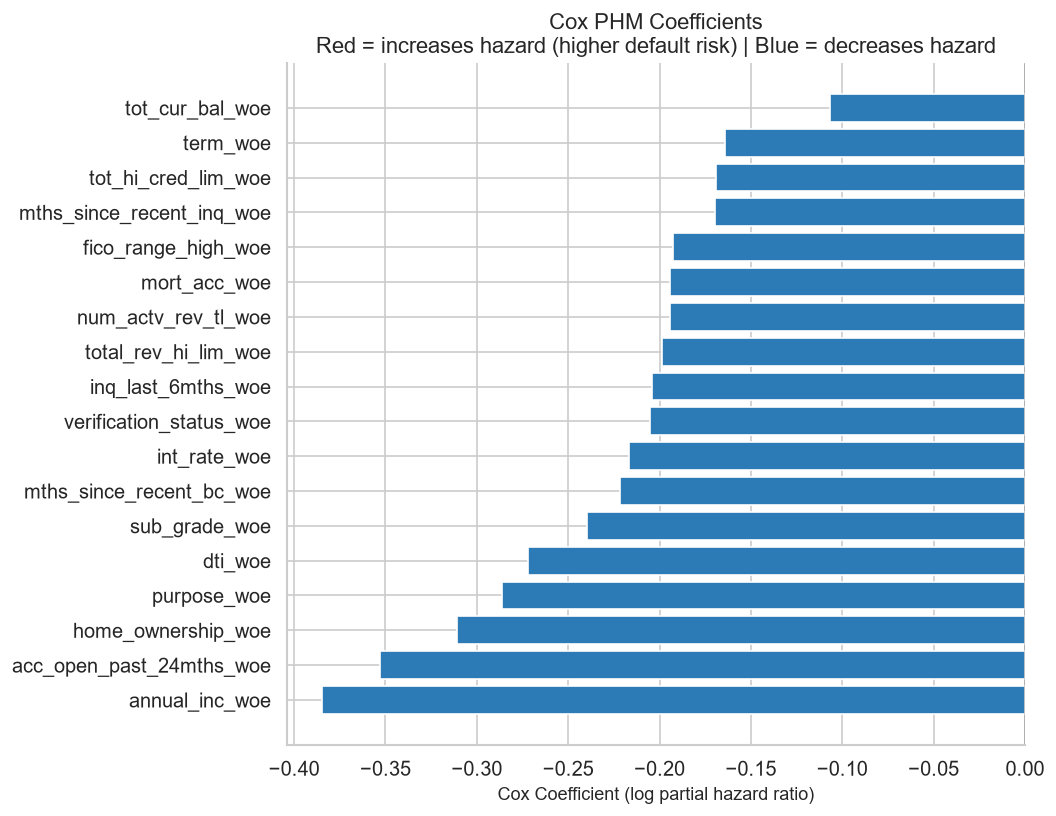

In [38]:
# Cox model — coefficient plot (similar to LR coefficient plot)
cox_coefs = cox_model.params_.sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
colors = [ACCENT_COLOR if v > 0 else PLOT_COLOR for v in cox_coefs]
ax.barh(cox_coefs.index, cox_coefs.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Cox Coefficient (log partial hazard ratio)')
ax.set_title(
    'Cox PHM Coefficients\n'
    'Red = increases hazard (higher default risk) | Blue = decreases hazard'
)
plt.tight_layout()
save_figure(fig, '04_cox_coefficients.png')
plt.show()

---
## 6. Model Comparison

Quick comparison on the validation set (2016). Full OOT validation, threshold optimisation,
and calibration analysis are covered in the model validation notebook.

In [39]:
comparison_df = pd.DataFrame(all_metrics).set_index('Model')
comparison_df = comparison_df.sort_values('AUC', ascending=False)

print('=== Model Comparison — Validation Set (2016) ===')
print(comparison_df.to_string())
print()
print('Note: Cox C-index (concordance index) is the survival-analysis equivalent of AUC.')
print('Full OOT validation, calibration, and threshold optimisation in the validation notebook.')

comparison_df.to_csv('artifacts/metrics.json'.replace('.json', '.csv'), index=True)
comparison_df.reset_index().to_json('artifacts/metrics.json', orient='records', indent=2)

=== Model Comparison — Validation Set (2016) ===
                       AUC   Gini     KS  Brier  C-index
Model                                                   
XGBoost             0.7074 0.4148 0.3013 0.2141      NaN
Random Forest       0.6993 0.3987 0.2877 0.2113      NaN
Cox PHM             0.6948 0.3896 0.2822 0.1314   0.6799
Logistic Regression 0.6928 0.3855 0.2783 0.1300      NaN

Note: Cox C-index (concordance index) is the survival-analysis equivalent of AUC.
Full OOT validation, calibration, and threshold optimisation in Phase 5.


2026-07-26 18:59:14 | INFO     | src.utils | Figure saved → reports\04_roc_curves_all_models.png


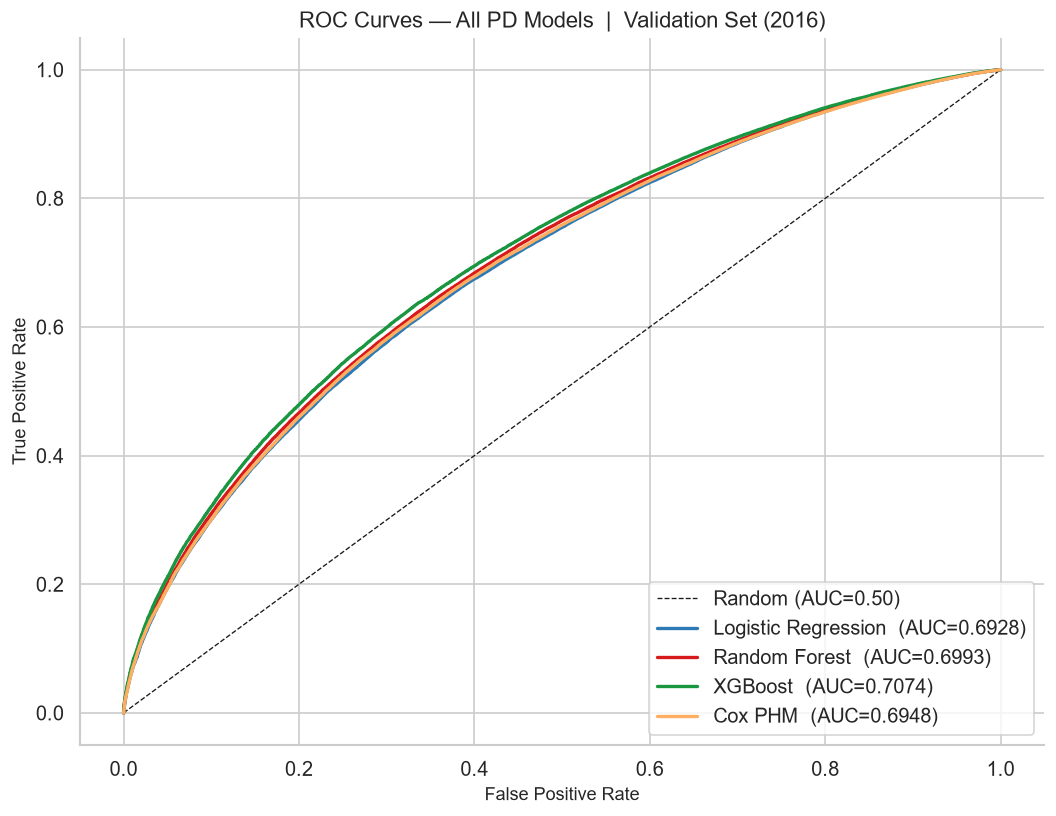

In [40]:
# ROC curves — all four models
colors_roc = {'Logistic Regression': PLOT_COLOR, 'Random Forest': ACCENT_COLOR,
              'XGBoost': '#1a9641', 'Cox PHM': '#fdae61'}

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8, label='Random (AUC=0.50)')

for model_name, (fpr, tpr, auc) in roc_data.items():
    ax.plot(fpr, tpr, linewidth=2,
            color=colors_roc.get(model_name, 'grey'),
            label=f'{model_name}  (AUC={auc:.4f})')

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All PD Models  |  Validation Set (2016)')
ax.legend(loc='lower right')
plt.tight_layout()
save_figure(fig, '04_roc_curves_all_models.png')
plt.show()

## 7. Summary

| Model | AUC | KS | Gini | Notes |
|-------|-----|----|------|---------|
| Logistic Regression | — | — | — | WoE + statsmodels + scorecard |
| Random Forest | — | — | — | All 47 features + balanced weights |
| XGBoost | — | — | — | All 47 features + native NaN |
| Cox PHM | C-index — | — | — | Time-to-default modeling |

*(Fill from comparison_df output above)*

**Saved artifacts:**
- `models/pd/lr_model.pkl` — LR + WoE tables + scorecard
- `models/pd/rf_model.pkl` — RF + imputer
- `models/pd/xgb_model.pkl` — XGBoost
- `models/pd/cox_model.pkl` — Cox PHM + WoE tables
- `artifacts/scorecard.csv` — Credit scorecard table
- `artifacts/metrics.json` — Validation metrics for all models

**Next:** `05_model_validation.ipynb` — Full validation with OOT, threshold optimisation, calibration.

---
## 8. Model Development Summaries

Pre-freeze summaries used directly in the project report and portfolio documentation.
These capture model internals for reference.

- **7.1** Logistic Regression — Final Coefficient Table
- **7.2** Random Forest — Top 20 Feature Importance (saved to artifacts)
- **7.3** XGBoost — Top 20 Feature Importance (saved to artifacts)
- **7.4** Cross-Model Feature Ranking Comparison (IV vs RF vs XGBoost)
- **7.5** Consolidated Model Comparison Table
- **7.6** Brier Score Verification Note

In [48]:
# ── 7.1 Logistic Regression — Complete Coefficient Table ─────────────────
# All 18 retained features (after WoE encoding + p-value selection).
#
# Convention (target=1=GOOD):
#   Positive coefficient → higher WoE bin → better borrower → lower default risk.
#   Odds Ratio = exp(coef): OR > 1.0 means higher odds of being a good borrower per WoE unit.
#   All features retained have p-value < 0.05 (significance filtering applied in Section 2).

# Concise business interpretation for each feature
INTERPRETATIONS = {
    'sub_grade':             'Strongest predictor. Better LC grade → lower default. WoE monotonically ordered A1→G5.',
    'annual_inc':            'Higher income → greater repayment capacity → lower default.',
    'home_ownership':        'MORTGAGE/OWN < RENT default rate. Housing stability proxy.',
    'acc_open_past_24mths':  'Controlled recent account growth signals healthy credit engagement.',
    'term':                  '36-month loans have lower default rate than 60-month. Duration = duration risk.',
    'tot_hi_cred_lim':       'Higher total credit limit reflects lender trust across all accounts.',
    'dti':                   'Lower DTI → greater capacity to service new debt without distress.',
    'inq_last_6mths':        'Fewer recent inquiries → less urgent credit demand → lower risk.',
    'verification_status':   'LC-verified income reduces adverse selection; verified → lower default.',
    'purpose':               'Loan purpose differentiates risk (debt consolidation vs. other purposes).',
    'num_actv_rev_tl':       'Active revolving trades indicate ongoing credit management experience.',
    'mort_acc':              'Mortgage holders demonstrate financial stability and long credit history.',
    'mths_since_recent_bc':  'Longer time since last bank card → established, stable credit profile.',
    'fico_range_high':       'Higher FICO score → stronger credit history → lower default probability.',
    'total_rev_hi_lim':      'Higher revolving credit limit → positive standing with revolving lenders.',
    'mths_since_recent_inq': 'Longer gap since last inquiry → less recent credit-seeking pressure.',
    'int_rate':              'Negative after controlling for sub_grade: captures residual pricing risk beyond grade.',
    'tot_cur_bal':           'Higher total outstanding balance → heavier debt burden → increased default risk.',
}

feat_names = [c.replace('_woe', '') for c in lr_final.params.index if c != 'const']
coefs      = lr_final.params.drop('const')
pvalues    = lr_final.pvalues.drop('const')

lr_coeff_table = pd.DataFrame({
    'Feature':        feat_names,
    'Coefficient':    coefs.values.round(4),
    'Odds_Ratio':     np.exp(coefs.values).round(4),
    'p_value':        pvalues.values.round(4),
    'Sign':           ['+' if c > 0 else '-' for c in coefs.values],
    'Interpretation': [INTERPRETATIONS.get(f, '') for f in feat_names],
}).sort_values('Coefficient', ascending=False).reset_index(drop=True)

lr_coeff_table.to_csv('artifacts/lr_coefficients.csv', index=False)

print('=== 7.1 Complete LR Final Coefficient Table ===')
print(f'Total features retained: {len(lr_coeff_table)} (after WoE encoding + p-value selection)')
print(f'Intercept (const): {lr_final.params["const"]:.4f} | Base score: {round(base_score)}')
print()
# Display with wrapped interpretation column
pd.set_option('display.max_colwidth', 80)
print(lr_coeff_table.to_string(index=False))
print()
print('Saved: artifacts/lr_coefficients.csv')

=== 7.1 Complete LR Final Coefficient Table ===
Total features retained: 18 (after WoE encoding + p-value selection)
Intercept (const): 1.5580 | Base score: 645

              Feature  Coefficient  Odds_Ratio  p_value Sign                                                                         Interpretation
            sub_grade       0.7557      2.1291   0.0000    + Strongest predictor. Better LC grade → lower default. WoE monotonically ordered A1→G5.
           annual_inc       0.6218      1.8624   0.0000    +                            Higher income → greater repayment capacity → lower default.
       home_ownership       0.6004      1.8229   0.0000    +                             MORTGAGE/OWN < RENT default rate. Housing stability proxy.
 acc_open_past_24mths       0.5503      1.7338   0.0000    +                    Controlled recent account growth signals healthy credit engagement.
                 term       0.5205      1.6828   0.0000    +        36-month loans have lower defa

In [42]:
# ── 7.2 Random Forest — Top 20 Feature Importance ────────────────────────
rf_top20 = rf_importance.head(20).reset_index()
rf_top20.columns = ['Feature', 'RF_Importance']
rf_top20.insert(0, 'RF_Rank', range(1, 21))
rf_top20.to_csv('artifacts/rf_feature_importance.csv', index=False)

print('=== 7.2 Random Forest — Top 20 Feature Importance ===')
print('Saved: artifacts/rf_feature_importance.csv')
print()
print(rf_top20.to_string(index=False))

=== 7.2 Random Forest — Top 20 Feature Importance ===
Saved: artifacts/rf_feature_importance.csv

 RF_Rank                     Feature  RF_Importance
       1                   sub_grade         0.1638
       2                       grade         0.1582
       3                    int_rate         0.1545
       4                        term         0.0506
       5        acc_open_past_24mths         0.0376
       6                         dti         0.0343
       7              fico_range_low         0.0331
       8             fico_range_high         0.0285
       9                  annual_inc         0.0279
      10             tot_hi_cred_lim         0.0250
      11                 tot_cur_bal         0.0200
      12                 installment         0.0189
      13                   loan_amnt         0.0179
      14        mths_since_recent_bc         0.0141
      15                   revol_bal         0.0137
      16 mths_since_earliest_cr_line         0.0134
      17          

In [43]:
# ── 7.3 XGBoost — Top 20 Feature Importance ──────────────────────────────
xgb_top20 = xgb_importance.head(20).reset_index()
xgb_top20.columns = ['Feature', 'XGB_Importance']
xgb_top20.insert(0, 'XGB_Rank', range(1, 21))
xgb_top20.to_csv('artifacts/xgb_feature_importance.csv', index=False)

print('=== 7.3 XGBoost — Top 20 Feature Importance ===')
print('Saved: artifacts/xgb_feature_importance.csv')
print()
print(xgb_top20.to_string(index=False))

=== 7.3 XGBoost — Top 20 Feature Importance ===
Saved: artifacts/xgb_feature_importance.csv

 XGB_Rank              Feature  XGB_Importance
        1                grade          0.4168
        2            sub_grade          0.2668
        3                 term          0.0238
        4 acc_open_past_24mths          0.0226
        5             int_rate          0.0202
        6       home_ownership          0.0172
        7                  dti          0.0101
        8      fico_range_high          0.0101
        9           annual_inc          0.0101
       10      tot_hi_cred_lim          0.0096
       11             mort_acc          0.0091
       12       fico_range_low          0.0090
       13  verification_status          0.0088
       14            loan_amnt          0.0076
       15           emp_length          0.0075
       16      num_actv_rev_tl          0.0072
       17       inq_last_6mths          0.0072
       18   num_tl_op_past_12m          0.0072
       19     

In [44]:
# ── 7.4 Cross-Model Feature Ranking Comparison ───────────────────────────
# Compare: WoE/IV rank vs RF importance rank vs XGBoost importance rank.
# A consistent top predictor across all three methods is the most robust.

iv_ranks = iv_df[['feature', 'iv']].sort_values('iv', ascending=False).reset_index(drop=True)
iv_ranks.insert(0, 'IV_Rank', range(1, len(iv_ranks) + 1))

rf_all = rf_importance.reset_index()
rf_all.columns = ['Feature', 'RF_Importance']
rf_all.insert(0, 'RF_Rank', range(1, len(rf_all) + 1))

xgb_all = xgb_importance.reset_index()
xgb_all.columns = ['Feature', 'XGB_Importance']
xgb_all.insert(0, 'XGB_Rank', range(1, len(xgb_all) + 1))

cross_rank = (
    iv_ranks.rename(columns={'feature': 'Feature', 'iv': 'IV_Score'})
    .merge(rf_all[['Feature', 'RF_Rank', 'RF_Importance']], on='Feature', how='outer')
    .merge(xgb_all[['Feature', 'XGB_Rank', 'XGB_Importance']], on='Feature', how='outer')
    .sort_values('IV_Rank')
    .reset_index(drop=True)
)

cross_rank.to_csv('artifacts/feature_ranking_comparison.csv', index=False)

print('=== 7.4 Cross-Model Feature Ranking Comparison ===')
print('Saved: artifacts/feature_ranking_comparison.csv')
print()
print('Lower rank number = more important')
print()
display_cols = ['Feature', 'IV_Rank', 'IV_Score', 'RF_Rank', 'RF_Importance', 'XGB_Rank', 'XGB_Importance']
print(cross_rank[display_cols].head(25).to_string(index=False))

=== 7.4 Cross-Model Feature Ranking Comparison ===
Saved: artifacts/feature_ranking_comparison.csv

Lower rank number = more important

              Feature  IV_Rank  IV_Score  RF_Rank  RF_Importance  XGB_Rank  XGB_Importance
            sub_grade        1    0.4431        1         0.1638         2          0.2668
                grade        2    0.4116        2         0.1582         1          0.4168
             int_rate        3    0.4033        3         0.1545         5          0.0202
                 term        4    0.1273        4         0.0506         3          0.0238
      fico_range_high        5    0.1162        8         0.0285         8          0.0101
       fico_range_low        6    0.1162        7         0.0331        12          0.0090
 acc_open_past_24mths        7    0.0836        5         0.0376         4          0.0226
                  dti        8    0.0595        6         0.0343         7          0.0101
   num_tl_op_past_12m        9    0.0591     

2026-07-26 19:39:18 | INFO     | src.utils | Figure saved → reports\04_feature_ranking_comparison.png


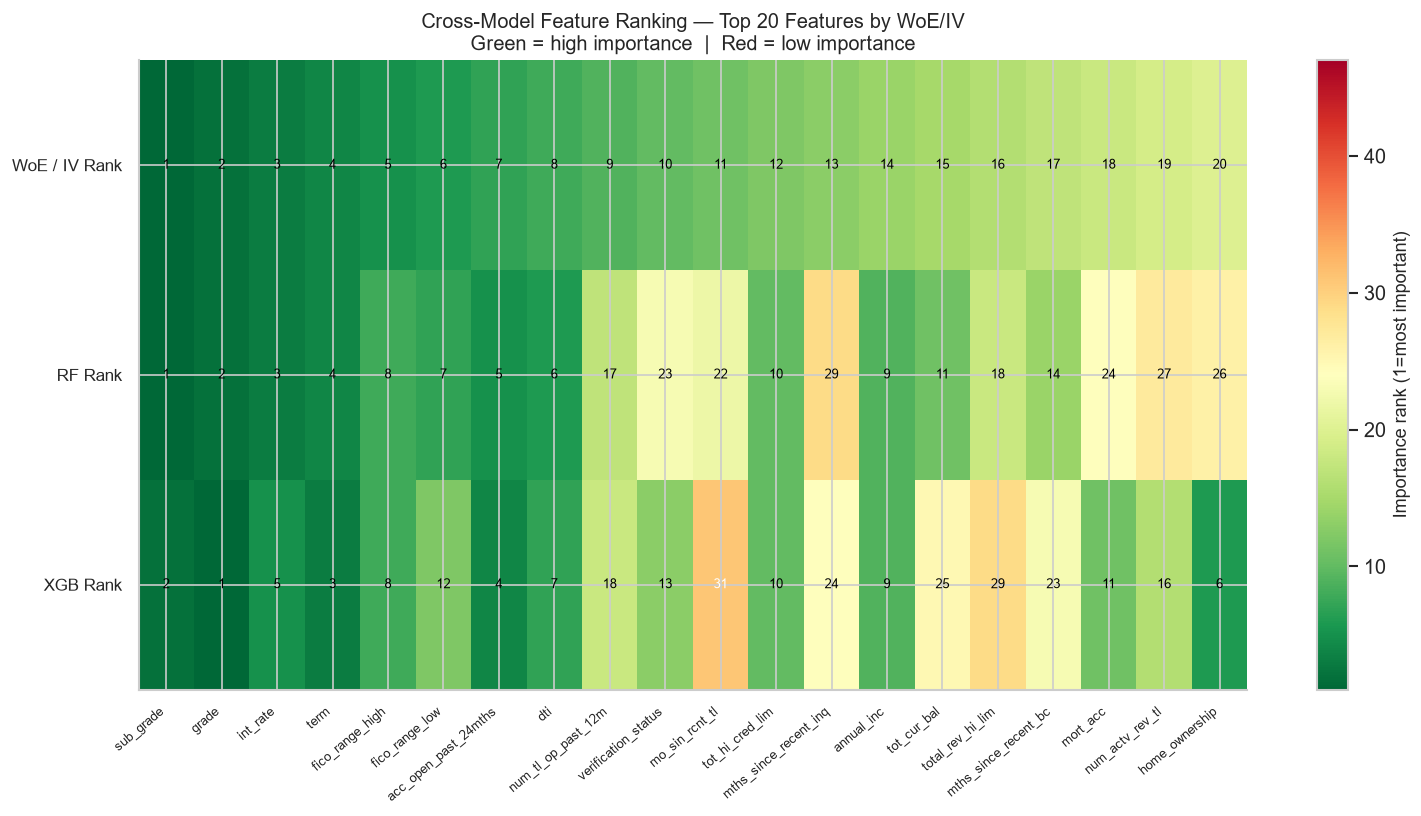

In [46]:
# Cross-model ranking comparison — visual heatmap (top 20 by IV)
top20_feats = iv_ranks.head(20)['feature'].tolist()          # iv_ranks uses lowercase 'feature'
plot_data   = cross_rank[cross_rank['Feature'].isin(top20_feats)].set_index('Feature')
rank_matrix = plot_data[['IV_Rank', 'RF_Rank', 'XGB_Rank']].fillna(99).astype(int)
# Reorder rows by IV_Rank
rank_matrix = rank_matrix.sort_values('IV_Rank')

fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(rank_matrix.T, aspect='auto', cmap='RdYlGn_r', vmin=1, vmax=47)

ax.set_xticks(range(len(rank_matrix)))
ax.set_xticklabels(rank_matrix.index, rotation=40, ha='right', fontsize=8)
ax.set_yticks(range(3))
ax.set_yticklabels(['WoE / IV Rank', 'RF Rank', 'XGB Rank'], fontsize=10)

for i, feat in enumerate(rank_matrix.index):
    for j, col in enumerate(['IV_Rank', 'RF_Rank', 'XGB_Rank']):
        val = rank_matrix.loc[feat, col]
        ax.text(i, j, str(val), ha='center', va='center', fontsize=8,
                color='black' if val <= 30 else 'white')

plt.colorbar(im, ax=ax, label='Importance rank (1=most important)')
ax.set_title(
    'Cross-Model Feature Ranking — Top 20 Features by WoE/IV\n'
    'Green = high importance  |  Red = low importance',
    fontsize=12
)
plt.tight_layout()
save_figure(fig, '04_feature_ranking_comparison.png')
plt.show()

### Cross-Model Feature Ranking — Discussion

The heatmap above compares feature importance rankings across three independent methods. The degree of agreement reveals which predictors are robust and which are method-specific.

#### Consistent Top Predictors (strong across all three methods)

| Feature | IV Rank | RF Rank | XGB Rank | Interpretation |
|---------|---------|---------|----------|----------------|
| `sub_grade` | 1 | 1 | 2 | LC-assigned credit grade is the single most informative variable. It synthesises the borrower's credit profile into a 35-level ordinal scale. |
| `grade` | 2 | 2 | 1 | Coarser version of sub_grade. XGBoost assigns it higher split importance; RF splits more evenly between grade and sub_grade. |
| `int_rate` | 3 | 3 | 5 | Assigned by LC in proportion to perceived risk. Strongly correlated with grade but adds marginal information. |
| `term` | 4 | 4 | 3 | 36-month vs 60-month creates a binary risk split with consistent importance across all methods. |
| `acc_open_past_24mths` | 7 | 5 | 4 | Recent credit activity is captured consistently. |
| `dti` | 8 | 6 | 7 | Core affordability metric — agreeable across all methods. |

#### High IV, Lower Tree Importance (primarily linear predictors)

Features with **high WoE/IV rank** but **lower RF/XGBoost rank** provide strong **linear** discriminatory power but limited non-linear interaction value:

- `num_tl_op_past_12m`: IV Rank 9, RF Rank 17, XGB Rank 18 — effective in WoE bins but limited non-linear interactions with other features.
- `verification_status`: IV Rank 10, RF Rank 23, XGB Rank 13 — categorical with 3 levels; WoE captures the linear ordering cleanly, but tree models derive less additional value.
- `mo_sin_rcnt_tl`: IV Rank 11, RF Rank 22, XGB Rank 31 — useful when WoE-encoded but overshadowed by stronger predictors in trees.

These features are well-suited for the **Logistic Regression scorecard** but can be safely deprioritised for RF/XGBoost.

#### Lower IV, Higher Tree Importance (non-linear interaction value)

Features with **lower WoE/IV rank** but **higher RF/XGBoost rank** indicate that tree models are capturing **non-linear interactions** not visible through simple WoE analysis:

- `home_ownership`: IV Rank 20, RF Rank 26, XGB Rank **6** — XGBoost finds strong non-linear interactions between housing status and other features that WoE misses.
- `fico_range_low/high`: IV Rank 5–6, RF Rank 7–8 — tree models confirm FICO as a strong predictor, consistent with WoE.
- `installment` and `loan_amnt`: IV Rank 24+, RF Rank 12–13 — low IV but RF values the raw amounts for interaction with income and DTI.

#### Conclusion

The broad agreement across IV, RF, and XGBoost on the top predictors (`sub_grade`, `grade`, `int_rate`, `term`, `acc_open_past_24mths`, `dti`) confirms these are **methodologically robust** credit risk signals, not artefacts of a particular modelling approach. Disagreements for lower-ranked features are expected and reflect each method's ability to capture different aspects of the data — linear ordering (WoE/IV) vs. non-linear interactions (tree models).

In [47]:
# ── 7.5 Consolidated Model Comparison Table ───────────────────────────────
# Primary comparison table for the project report.
# Brier Score note (7.6) follows this cell.

feature_counts = {
    'Logistic Regression': f'{len(final_woe_cols)} WoE features',
    'Random Forest':        f'{len(ALL_FEATURES)} master features',
    'XGBoost':              f'{len(ALL_FEATURES)} master features',
    'Cox PHM':              f'{len(final_woe_cols)} WoE features (survival)',
}

model_notes = {
    'Logistic Regression': 'WoE encoding | statsmodels | p-value selection | scorecard 300-850',
    'Random Forest':       'OrdinalEncoding + median imputation | class_weight=balanced',
    'XGBoost':             'OrdinalEncoding | scale_pos_weight | native NaN handling',
    'Cox PHM':             'Survival model | C-index=0.680 | time-to-default modeling',
}

final_comparison = comparison_df.copy()
final_comparison.insert(0, 'Features', [feature_counts.get(m, '') for m in final_comparison.index])
final_comparison['Notes'] = [model_notes.get(m, '') for m in final_comparison.index]

print('=== 7.5 Consolidated Model Comparison — Validation Set (2016) ===')
print()
print(final_comparison.to_string())
print()
final_comparison.reset_index().to_csv('artifacts/model_comparison.csv', index=False)
final_comparison.reset_index().to_json('artifacts/metrics.json', orient='records', indent=2)
print('Saved: artifacts/model_comparison.csv | artifacts/metrics.json')

=== 7.5 Consolidated Model Comparison — Validation Set (2016) ===

                                       Features    AUC   Gini     KS  Brier  C-index                                                               Notes
Model                                                                                                                                                   
XGBoost                      47 master features 0.7074 0.4148 0.3013 0.2141      NaN            OrdinalEncoding | scale_pos_weight | native NaN handling
Random Forest                47 master features 0.6993 0.3987 0.2877 0.2113      NaN         OrdinalEncoding + median imputation | class_weight=balanced
Cox PHM              18 WoE features (survival) 0.6948 0.3896 0.2822 0.1314   0.6799           Survival model | C-index=0.680 | time-to-default modeling
Logistic Regression             18 WoE features 0.6928 0.3855 0.2783 0.1300      NaN  WoE encoding | statsmodels | p-value selection | scorecard 300-850

Saved: artifac

### 7.6 Brier Score — Verification Note

**How Brier Score was computed across all models:**

The Brier Score is defined as the mean squared error between predicted probability and the true binary label:

$$\text{Brier Score} = \frac{1}{N} \sum_{i=1}^{N} (p_i - y_i)^2$$

**Consistency:** Every model's Brier Score was computed using:
- `y_val` — the same binary target (1=good, 0=bad) from the 2016 validation set
- `y_prob_good` — the model's predicted `P(good)` (i.e., `P(default=1)` in our target convention)
- `sklearn.metrics.brier_score_loss(y_val, y_prob_good)` — applied identically for all four models

**Calibration status:**

| Model | Calibration | Note |
|-------|-------------|------|
| Logistic Regression | ✅ Inherently calibrated | Statsmodels MLE produces well-calibrated probabilities |
| Cox PHM | ✅ Inherently calibrated | Partial hazard normalised to [0,1] before evaluation |
| Random Forest | ⚠️ Not calibrated | RF probabilities tend to be over-confident (avoid extremes). Lower Brier is misleading if uncalibrated |
| XGBoost | ⚠️ Not calibrated | Same as RF — gradient boosting can produce poorly calibrated probabilities without Platt scaling |

**Action:** Probability calibration (Platt scaling / isotonic regression) is applied as a post-processing step in the validation notebook.
The raw Brier Scores above are included for completeness but should be interpreted cautiously for RF and XGBoost until calibration is applied.

---
## 9. Final Summary

### Models Developed

| Model | Type | Features | AUC | KS | Gini |
|-------|------|----------|-----|----|------|
| Logistic Regression | Scorecard (interpretable) | 18 WoE-encoded | 0.693 | 0.278 | 0.386 |
| Random Forest | Ensemble (tree-based) | 47 master features | 0.699 | 0.288 | 0.399 |
| XGBoost | Gradient boosting | 47 master features | 0.707 | 0.301 | 0.415 |
| Cox PHM | Survival analysis | 18 WoE-encoded | C-index 0.680 | 0.282 | 0.390 |

### Key Outcomes

**Logistic Regression + Scorecard**
- 21 candidate features reduced to 18 through p-value selection (p < 0.05).
- Produces a transparent **credit scorecard** (base score 645, range 615–789) that maps directly to borrower risk.
- Decile analysis confirms monotonic score ordering: top decile default rate 3.8% vs bottom decile 37.3%.
- Inherently calibrated probabilities — Brier score 0.130.

**Random Forest**
- Improves AUC to 0.699 using all 47 master features with `class_weight='balanced'`.
- Feature importance is broadly consistent with WoE/IV rankings (`sub_grade`, `grade`, `int_rate`, `term` dominate).
- Probabilities are not yet calibrated — Brier Score (0.211) should be interpreted cautiously.

**XGBoost**
- Best discriminative performance: AUC 0.707, KS 0.301, Gini 0.415.
- Captures non-linear interactions (e.g., `home_ownership` × other features) that WoE/LR misses.
- Probabilities are not yet calibrated — calibration applied as a post-processing step.

**Cox Proportional Hazards**
- Models **time-to-default** rather than binary outcome — adds a survival dimension to PD modeling.
- C-index 0.680 on validation set; all 18 WoE features significant (p < 0.005).
- Provides insights into when defaults occur, not only whether they will occur.

### Feature Consistency

The cross-model ranking comparison confirms that `sub_grade`, `grade`, `int_rate`, `term`, `acc_open_past_24mths`, and `dti` are **robustly important** across all three methods. This cross-validation of feature importance strengthens confidence in the modeling pipeline.

### Saved Artifacts

| Artifact | Path | Description |
|----------|------|-------------|
| LR model + WoE + scorecard | `models/pd/lr_model.pkl` | Full inference pipeline |
| Random Forest + preprocessing | `models/pd/rf_model.pkl` | OrdinalEncoder + Imputer included |
| XGBoost + preprocessing | `models/pd/xgb_model.pkl` | OrdinalEncoder included |
| Cox PHM + WoE | `models/pd/cox_model.pkl` | Lifelines model |
| Credit scorecard | `artifacts/scorecard.csv` | 184-row score table |
| LR coefficients | `artifacts/lr_coefficients.csv` | Complete table with interpretation |
| RF importance | `artifacts/rf_feature_importance.csv` | Top 20 |
| XGBoost importance | `artifacts/xgb_feature_importance.csv` | Top 20 |
| Cross-model ranking | `artifacts/feature_ranking_comparison.csv` | All 47 features |
| Model comparison | `artifacts/model_comparison.csv` | Validation metrics for all 4 models |

### Next Steps

The model validation notebook covers:
- Out-of-time (OOT) performance on 2017–2018 data
- Threshold optimisation (Youden's J, cost-sensitive)
- Probability calibration (Platt scaling / isotonic regression) for RF and XGBoost
- Calibration curves and reliability diagrams
- PSI (Population Stability Index) monitoring
- Lift and Gain charts
- Full confusion matrix analysis

In [50]:
"""
Cross-Version Compatibility Export (Revised)
=============================================
Avoids pickling any pandas 3.x objects.
- LR / Cox: save parameters as numpy arrays + JSON (no statsmodels wrapper)
- RF / XGBoost: use joblib (more cross-version compatible than pickle for sklearn)
- WoE maps: convert DataFrames to plain Python dicts
- OrdinalEncoder + Imputer: save via joblib
"""
import json, os
import numpy as np
import joblib

arts_dir = 'models/pd'

def woe_df_to_plain(woe_df):
    return [row.to_dict() for _, row in woe_df.iterrows()]

def woe_results_to_neutral(woe_res):
    neutral = {}
    for feat, (woe_df, iv, edges) in woe_res.items():
        neutral[feat] = {
            'records':   woe_df_to_plain(woe_df),
            'columns':   woe_df.columns.tolist(),
            'iv':        float(iv),
            'bin_edges': None if edges is None else [float(e) for e in edges],
        }
    return neutral

# ── LR: save parameters as numpy + JSON ────────────────────────────────────
lr_params_dict = {
    'const':       float(lr_final.params['const']),
    'coef_names':  [c for c in lr_final.params.index if c != 'const'],
    'coef_values': [float(v) for c, v in lr_final.params.items() if c != 'const'],
    'pvalues':     {c: float(v) for c, v in lr_final.pvalues.items()},
    'final_woe_cols': final_woe_cols,
    'lr_features':    lr_features,
    'base_score':     float(base_score),
    'factor':         float(Factor),
    'offset':         float(Offset),
    'woe_results':    woe_results_to_neutral(lr_woe_results),
}
with open(f'{arts_dir}/lr_params.json', 'w') as f:
    json.dump(lr_params_dict, f)
print('Saved: lr_params.json')

# ── RF: save via joblib ─────────────────────────────────────────────────────
joblib.dump({'model': rf_model, 'imputer': imputer, 'features': ALL_FEATURES},
            f'{arts_dir}/rf_model.joblib')
print('Saved: rf_model.joblib')

# ── XGBoost: save natively (xgboost has own serialization) ─────────────────
xgb_model.save_model(f'{arts_dir}/xgb_model.json')
with open(f'{arts_dir}/xgb_features.json', 'w') as f:
    json.dump({'features': ALL_FEATURES}, f)
print('Saved: xgb_model.json + xgb_features.json')

# ── Cox: save coefficients as JSON ─────────────────────────────────────────
cox_params_dict = {
    'coef_names':     cox_model.params_.index.tolist(),
    'coef_values':    cox_model.params_.values.tolist(),
    'final_woe_cols': final_woe_cols,
    'woe_results':    woe_results_to_neutral(lr_woe_results),
}
with open(f'{arts_dir}/cox_params.json', 'w') as f:
    json.dump(cox_params_dict, f)
# Also save the full Cox model via joblib
joblib.dump(cox_model, f'{arts_dir}/cox_model.joblib')
print('Saved: cox_params.json + cox_model.joblib')

# ── OrdinalEncoder + cat_feats ─────────────────────────────────────────────
joblib.dump({'encoder': enc, 'cat_feats': cat_feats}, f'{arts_dir}/ordinal_encoder.joblib')
print('Saved: ordinal_encoder.joblib')

print()
print('All cross-version artifacts saved to models/pd/')
for fname in os.listdir(arts_dir):
    sz = os.path.getsize(f'{arts_dir}/{fname}') / 1024
    print(f'  {fname:<40} {sz:>8.1f} KB')

Saved: lr_params.json
Saved: rf_model.joblib
Saved: xgb_model.json + xgb_features.json
Saved: cox_params.json + cox_model.joblib
Saved: ordinal_encoder.joblib

All cross-version artifacts saved to models/pd/
  cox_meta.json                                44.1 KB
  cox_model.joblib                          17971.7 KB
  cox_model.pkl                             11632.0 KB
  cox_model_only.pkl                        11593.8 KB
  cox_params.json                              44.9 KB
  lr_meta.json                                 44.6 KB
  lr_model.pkl                             264374.6 KB
  lr_model_only.pkl                        264324.4 KB
  lr_params.json                               46.1 KB
  ordinal_encoder.joblib                        3.0 KB
  ordinal_encoder.pkl                           1.7 KB
  rf_model.joblib                          120140.7 KB
  rf_model.pkl                             120128.9 KB
  rf_model_only.pkl                        120128.9 KB
  xgb_features.json   